# pIAno — Visual-to-Music Generation with Mistral 7B + CLIP

## 1 - Environment setup

In [1]:
# 1. INSTALLATIONS
!pip install -q transformers datasets peft trl bitsandbytes accelerate music21 open_clip_torch Pillow ipywidgets

# 2. ALL IMPORTS
import torch, gc, os, re, pandas as pd, random, json
import matplotlib.pyplot as plt
import music21
import open_clip
import ipywidgets as widgets
from PIL import Image
from IPython.display import display, Audio, FileLink, Image as IPImage, HTML
from datasets import load_dataset
from transformers import (
    AutoModelForCausalLM, 
    AutoTokenizer, 
    BitsAndBytesConfig, 
    TrainingArguments
)
from peft import (
    LoraConfig, 
    get_peft_model, 
    prepare_model_for_kbit_training, 
    PeftModel
)
from trl import SFTTrainer

# 3. KAGGLE PATH CONFIGURATION
SAVE_PATH = "/kaggle/working/Mistral_Music_Project"
if not os.path.exists(SAVE_PATH):
    os.makedirs(SAVE_PATH)

MODEL_ID = "mistralai/Mistral-7B-v0.1"
DATA_FILE = os.path.join(SAVE_PATH, "dataset_ia_musique_vision.jsonl")
MODEL_SAVE_PATH = os.path.join(SAVE_PATH, "mistral_vision_final")

# RAM cleaning
gc.collect()
torch.cuda.empty_cache()

# CUDA safety flags
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

# Load CLIP (Vision Tower)
clip_model, _, preprocess = open_clip.create_model_and_transforms('ViT-B-32', pretrained='laion2b_s34b_b79k')
clip_model = clip_model.to("cuda").eval()

print("Kaggle environment ready.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 528.8/528.8 kB 10.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 31.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 61.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.3 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/torch/backends/__init__.py:46: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:80.)
  self.setter(val)


open_clip_model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Kaggle environment ready.


## 2 - Dataset Preparation

In [2]:
def prepare_vision_dataset(target_ratio=0.5, batch_size=128):
    raw_examples = []
    seen_abc = set()
    skipped_incomplete = 0
    skipped_duplicate = 0

    print("Loading and filtering data...")
    ds = load_dataset("sander-wood/irishman", split="train").select(range(10000))

    prompts_to_encode = []
    temp_data = []

    for ex in ds:
        abc = ex.get('abc notation', '').strip()
        control = ex.get('control code', '')
        if not abc or not abc.startswith('X:'): continue

        abc_clean = re.sub(r'%.*', '', abc)
        abc_clean = re.sub(r'\n\s*\n', '\n', abc_clean).strip()

        if abc_clean in seen_abc:
            skipped_duplicate += 1
            continue

        match_k = re.search(r'K:\s*([A-Ga-g][#b]?)(m|min|maj|M|dor|phr|aeo)?', abc_clean)
        match_m = re.search(r'M:\s*([\d/]+)', abc_clean)
        match_l = re.search(r'L:\s*([\d/]+)', abc_clean)

        if not match_k or not match_m or not match_l:
            skipped_incomplete += 1
            continue

        seen_abc.add(abc_clean)

        key_note = match_k.group(1).upper()
        mode = (match_k.group(2) or "maj").lower()
        emotion = "sad and dark" if mode in ['m', 'min', 'dor', 'phr', 'aeo'] else "happy and upbeat"

        prompt_image = (f"A {emotion} traditional Irish tune in {match_m.group(1)}, "
                        f"base note {match_l.group(1)}, key {key_note}{mode}, "
                        f"structure: {control.replace(chr(10), ' | ').strip()}")

        prompts_to_encode.append(prompt_image)
        temp_data.append({"abc": abc_clean, "emotion": emotion})

    print(f"Encoding {len(prompts_to_encode)} prompts with CLIP (Batch size: {batch_size})...")
    all_embeddings = []

    for i in range(0, len(prompts_to_encode), batch_size):
        batch_prompts = prompts_to_encode[i : i + batch_size]
        with torch.no_grad():
            tokens = open_clip.tokenize(batch_prompts).to("cuda")
            embeddings = clip_model.encode_text(tokens)
            embeddings /= embeddings.norm(dim=-1, keepdim=True)
            all_embeddings.extend(embeddings.cpu().numpy().tolist())
        if i % (batch_size * 10) == 0:
            print(f"  Progress: {i}/{len(prompts_to_encode)}")

    sad_examples = []
    happy_examples = []
    prompts_varies = [
        "Generate a traditional Irish tune based on this visual.",
        "Compose a melody that matches the style of this image.",
        "Write an ABC notation score inspired by this picture.",
        "Generate an Irish tune in ABC based on the image.",
        "Generate an ABC notation using this image."
    ]

    for i in range(len(temp_data)):
        abc_raw = temp_data[i]['abc']
        lines = abc_raw.split('\n')
        abc_body = "\n".join(lines[1:]).strip() if lines[0].startswith('X:') else abc_raw.strip()
        instruction = random.choice(prompts_varies)

        entry = {
            "text": f"<s>[INST] <IMAGE_EMBED>\n{instruction} [/INST]\nX:1\n{abc_body}</s>",
            "image_features": all_embeddings[i]
        }
        
        if temp_data[i]['emotion'].startswith("sad"):
            sad_examples.append(entry)
        else:
            happy_examples.append(entry)

    n_target = min(len(sad_examples), len(happy_examples))
    balanced_dataset = random.sample(sad_examples, n_target) + random.sample(happy_examples, n_target)
    random.shuffle(balanced_dataset)

    pd.DataFrame(balanced_dataset).to_json(DATA_FILE, orient="records", lines=True)

    print("-" * 30)
    print(f"Done! Total: {len(balanced_dataset)} | Sad: {n_target} | Happy: {n_target}")
    print(f"File saved to: {DATA_FILE}")

prepare_vision_dataset(target_ratio=0.5)

Chargement et filtrage des données...


README.md: 0.00B [00:00, ?B/s]

train.json:   0%|          | 0.00/80.0M [00:00<?, ?B/s]

validation.json: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/214122 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2162 [00:00<?, ? examples/s]

Encodage de 9959 prompts avec CLIP (Batch size: 128)...
  Progrès : 0/9959
  Progrès : 1280/9959
  Progrès : 2560/9959
  Progrès : 3840/9959
  Progrès : 5120/9959
  Progrès : 6400/9959
  Progrès : 7680/9959
  Progrès : 8960/9959
------------------------------
Terminé ! Total : 4022 | Sad: 2011 | Happy: 2011
Fichier sauvegardé dans : /kaggle/working/Mistral_Music_Project/dataset_ia_musique_vision_v5.jsonl


## 3 - Model Setup for Training

In [3]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.padding_side = "left"
tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",
    dtype=torch.float16,
)

model.gradient_checkpointing_enable()
model = prepare_model_for_kbit_training(model)

config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.05,
    task_type="CAUSAL_LM"
)

model = get_peft_model(model, config)
model.print_trainable_parameters()

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/996 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/493k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

...

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

trainable params: 41,943,040 || all params: 7,283,675,136 || trainable%: 0.5758


## 4 - Multimodal Collator and Training

In [5]:
class MultimodalCollator:
    def __init__(self, tokenizer, image_token_id):
        self.tokenizer = tokenizer
        self.image_token_id = image_token_id

    def __call__(self, features):
        # 1. Text preparation (stays on CPU)
        texts = [f["text"] for f in features]
        batch = self.tokenizer(
            texts, 
            return_tensors="pt", 
            padding=True, 
            truncation=True, 
            max_length=512
        )
        
        # 2. Retrieve image features (stays on CPU)
        img_feats = [torch.tensor(f["image_features"], dtype=torch.float16) for f in features]
        img_feats = torch.stack(img_feats) 

        # 3. Build inputs_embeds
        # Using .cpu() explicitly to ensure nothing is moved to GPU prematurely
        # get_input_embeddings() returns a layer that may live on GPU; we force CPU computation
        embeddings_layer = model.get_input_embeddings().cpu()
        inputs_embeds = embeddings_layer(batch["input_ids"]).clone().detach()

        # 4. Image injection (still on CPU)
        for i in range(len(texts)):
            idx = (batch["input_ids"][i] == self.image_token_id).nonzero(as_tuple=True)[0]
            if len(idx) > 0:
                # Replace special token embeddings with CLIP features
                inputs_embeds[i, idx[0], :img_feats.shape[1]] = img_feats[i]

        labels = batch["input_ids"].clone()
        
        # IMPORTANT: Return CPU tensors. The Trainer will handle the .to("cuda") transfer.
        return {
            "inputs_embeds": inputs_embeds,
            "attention_mask": batch["attention_mask"],
            "labels": labels
        }

# --- Rest of the cell unchanged ---
image_token_id = tokenizer.encode("<IMAGE_EMBED>", add_special_tokens=False)[0]
custom_collator = MultimodalCollator(tokenizer, image_token_id)

training_args = TrainingArguments(
    output_dir="./results",
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    learning_rate=1e-4,
    weight_decay=0.01,
    max_grad_norm=1.0,
    optim="paged_adamw_8bit",
    lr_scheduler_type="cosine",
    warmup_steps=20,
    num_train_epochs=1,
    max_steps=150,
    logging_steps=5,
    save_strategy="no",
    remove_unused_columns=False,
    report_to="none",
    dataloader_pin_memory=False # Optional: disables pin_memory for safety
)

raw_dataset = load_dataset("json", data_files=DATA_FILE, split="train")

trainer = SFTTrainer(
    model=model,
    train_dataset=raw_dataset,
    args=training_args,
    data_collator=custom_collator,
)

# Ensure model is ready but let the trainer handle tensor placement
model.to(torch.float16)
print("Launching training...")
trainer.train()

trainer.model.save_pretrained(MODEL_SAVE_PATH)
tokenizer.save_pretrained(MODEL_SAVE_PATH)
print(f"Saved to: {MODEL_SAVE_PATH}")

🚀 Lancement de l'entraînement corrigé...


Step,Training Loss
5,3.079614
10,1.921658
15,1.550089
20,1.458889
25,1.359068
30,1.416436
35,1.227094
40,1.333617
45,1.232546
50,1.166203


Sauvegardé dans : /kaggle/working/Mistral_Music_Project/mistral_vision_final_v5


## 5 - Learning Curve

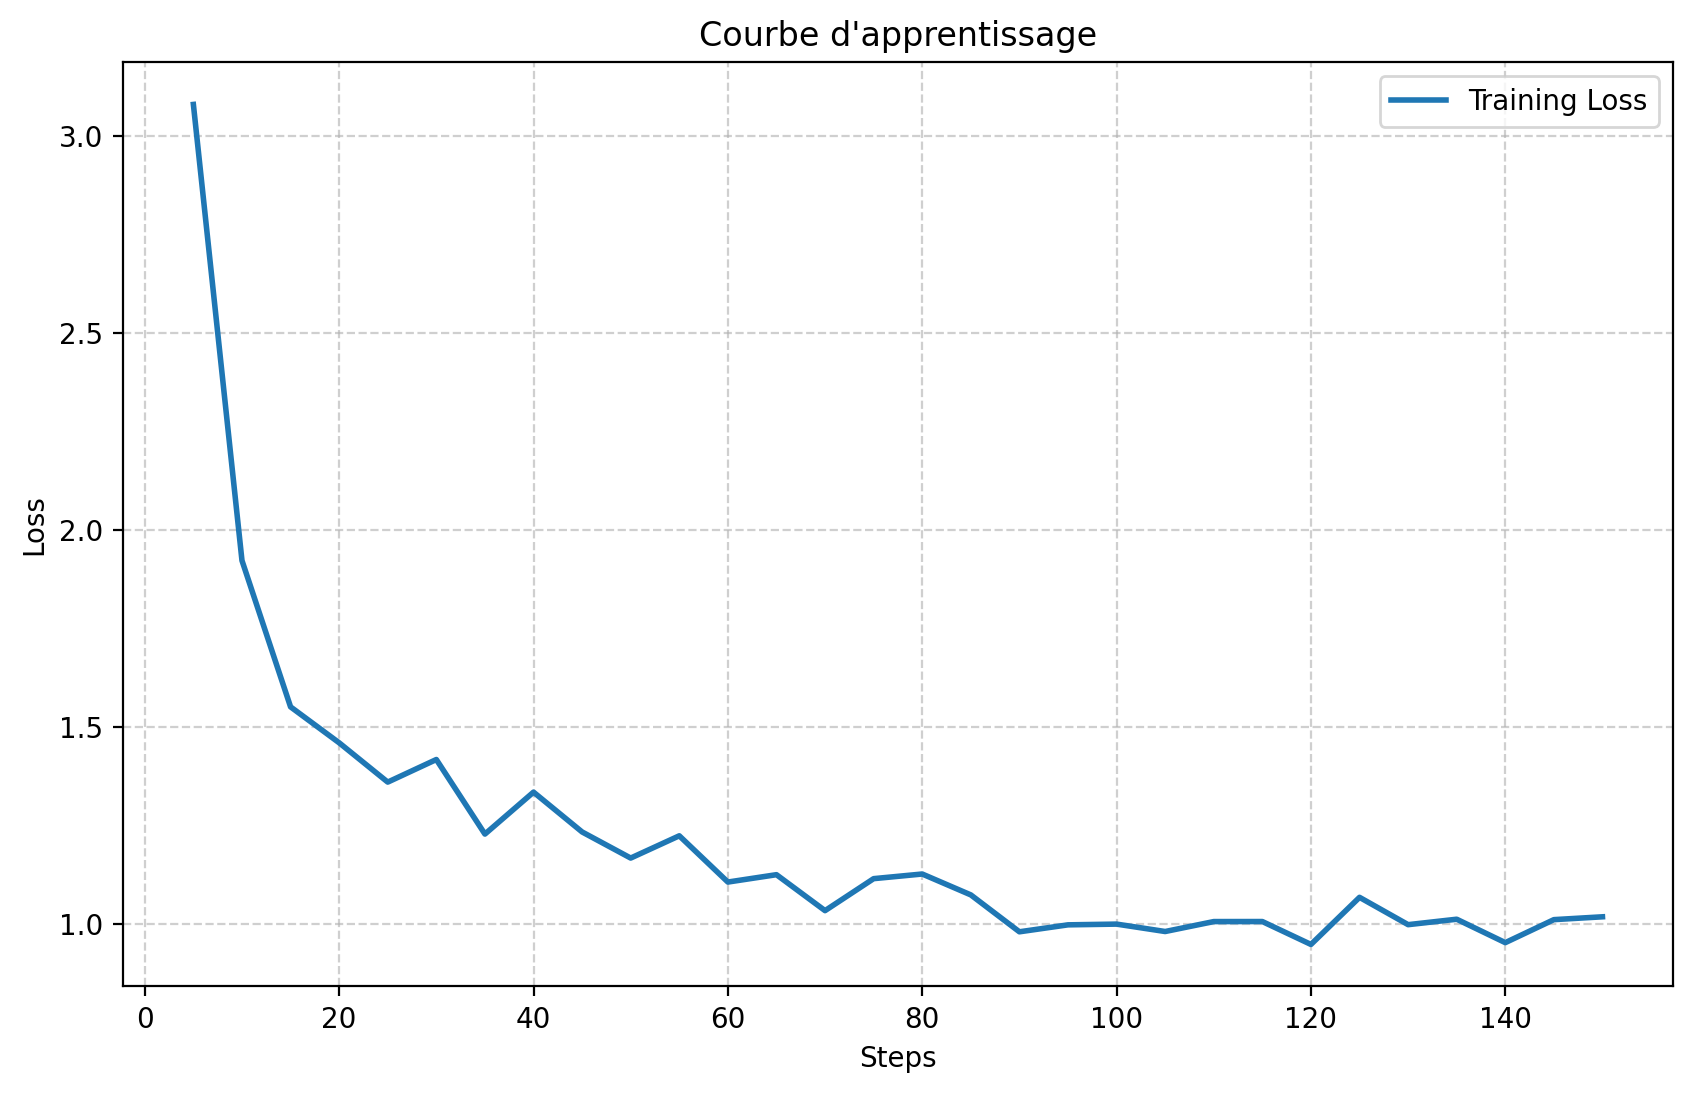

In [6]:
history = trainer.state.log_history
train_loss = [x['loss'] for x in history if 'loss' in x]
steps = [x['step'] for x in history if 'loss' in x]

plt.figure(figsize=(10, 6))
plt.plot(steps, train_loss, label='Training Loss', color='#1f77b4', linewidth=2)
plt.title('Learning Curve')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

## 6 - Model Loading (Inference)

In [2]:
# --- DETECTED PATH ---
ADAPTER_PATH = "/kaggle/input/datasets/elosetrabut/piano-data"
BASE_MODEL_ID = "mistralai/Mistral-7B-v0.1"

print(f"Loading from: {ADAPTER_PATH}")

# 1. Tokenizer loading
# local_files_only forces the use of local files (tokenizer.json, etc.)
tokenizer = AutoTokenizer.from_pretrained(
    ADAPTER_PATH, 
    local_files_only=True
)

# 2. 4-bit quantization config (Kaggle GPU optimization)
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

# 3. Load base Mistral 7B model
print("Loading Mistral 7B base model...")
base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto"
)

# 4. Apply LoRA adapters
print("Applying musical LoRA adapters...")
model = PeftModel.from_pretrained(
    base_model, 
    ADAPTER_PATH,
    local_files_only=True
)

model.eval()
print("pIAno model loaded and ready for generation!")

Loading from: /kaggle/input/datasets/elosetrabut/piano-data
Loading Mistral 7B base model...


config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

Applying musical LoRA adapters...
pIAno model loaded and ready for generation!


## 7 - Music Generation Functions

In [3]:
def generer_musique_flexible(image_paths, weights=None):
    if weights is None: 
        weights = [1.0] * len(image_paths)
    
    prompts_entrainement = [
        "Generate a traditional Irish tune based on this visual.",
        "Compose a melody that matches the style of this image.",
        "Write an ABC notation score inspired by this picture.",
        "Generate an Irish tune in ABC based on the image.",
        "Generate an ABC notation using this image."
    ]
    
    device = "cuda" if torch.cuda.is_available() else "cpu"
    target_dtype = model.get_input_embeddings().weight.dtype
    
    all_features = []
    with torch.no_grad():
        for path in image_paths:
            image = Image.open(path).convert("RGB")
            img_t = preprocess(image).unsqueeze(0).to(device)
            features = clip_model.encode_image(img_t)
            features /= features.norm(dim=-1, keepdim=True)
            all_features.append(features)

        weighted_features = torch.zeros_like(all_features[0], dtype=all_features[0].dtype, device=device)
        for f, w in zip(all_features, weights):
            weighted_features += f * w
        fusion_features = (weighted_features / sum(weights)).to(target_dtype)

        final_embedding = torch.zeros((1, 1, 4096), device=device, dtype=target_dtype)
        final_embedding[:, :, :fusion_features.shape[-1]] = fusion_features.unsqueeze(1)

        instruction = random.choice(prompts_entrainement)
        prompt = f"<s>[INST] <IMAGE_EMBED>\n{instruction} [/INST]\nX:1\n"
        
        inputs = tokenizer(prompt, return_tensors="pt", padding=True).to(device)
        inputs_embeds = model.get_input_embeddings()(inputs.input_ids).clone().detach()
        
        token_id_img = tokenizer.encode("<IMAGE_EMBED>", add_special_tokens=False)[0]
        idx = (inputs.input_ids == token_id_img).nonzero(as_tuple=True)[1]
        if len(idx) > 0:
            inputs_embeds[:, idx, :] = final_embedding

        outputs = model.generate(
            inputs_embeds=inputs_embeds,
            attention_mask=inputs.attention_mask,
            pad_token_id=tokenizer.eos_token_id,
            max_new_tokens=350,
            temperature=0.75,
            repetition_penalty=1.2,
            do_sample=True
        )

    raw_output = tokenizer.decode(outputs[0], skip_special_tokens=True)
    
    abc_output = raw_output.split("[/INST]")[-1].strip() if "[/INST]" in raw_output else raw_output.strip()
    
    # Remove illegal ABC characters
    abc_output = re.sub(r'[^a-gA-G0-9\s|/,\':\n\^=_\[\]\(\)]', '', abc_output)
    
    return abc_output

# Clean ABC while preserving existing headers
def nettoyer_abc(abc_string):

    lines = abc_string.split("\n")

    headers = {}
    music_lines = []

    header_keys = ["X:", "T:", "M:", "L:", "K:", "R:", "Z:", "C:"]

    for line in lines:

        line = line.strip()
        if not line:
            continue

        found = False

        for h in header_keys:
            if line.startswith(h):

                # Keep only the first occurrence of each header
                if h not in headers:
                    headers[h] = line

                found = True
                break

        if not found:
            music_lines.append(line)

    # Add only missing headers with default values
    headers.setdefault("X:", "X:1")
    headers.setdefault("T:", "T:AI Composition")
    headers.setdefault("M:", "M:4/4")
    headers.setdefault("L:", "L:1/8")
    headers.setdefault("K:", "K:C")

    ordered = ["X:", "T:", "M:", "L:", "K:"]

    final_lines = []

    for h in ordered:
        if h in headers:
            final_lines.append(headers[h])

    for h in headers:
        if h not in ordered:
            final_lines.append(headers[h])

    final_lines.extend(music_lines)

    return "\n".join(final_lines)
    
def exporter_midi(abc_string, output_name="fusion_resultat"):

    try:

        print("Cleaning score...")

        abc_clean = nettoyer_abc(abc_string)

        score = music21.converter.parse(
            f"str: {abc_clean}",
            format="abc"
        )

        score.write(
            "midi",
            fp=f"{output_name}.mid"
        )

        print("MIDI export successful")
        return True

    except Exception as e:

        print("music21 error:", e)

        try:

            print("Attempting rescue export...")

            notes_only = re.sub(
                r"[^A-Ga-g0-9\s|/']",
                "",
                abc_string
            )

            rescue_abc = f"""
            X:1
            T:Recovered
            M:4/4
            L:1/8
            K:C
            {notes_only}
            """

            score = music21.converter.parse(
                f"str: {rescue_abc}",
                format="abc"
            )

            score.write(
                "midi",
                fp=f"{output_name}.mid"
            )

            print("Rescue export successful")
            return True

        except Exception as e2:

            print("Total failure:", e2)
            return False

    except Exception as e:
        print(f"MIDI structure error: {e}. Attempting rescue...")
        try:
            # Last resort: keep only pure notes (A-G)
            notes_only = re.sub(r'[^a-gA-G0-9\s|/\']', '', "\n".join(music_content))
            rescue_abc = f"X:1\nM:4/4\nL:1/8\nK:C\n{notes_only}"
            score_s = music21.converter.parse(f"str: {rescue_abc}", format="abc")
            score_s.write("midi", fp=f"{output_name}.mid")
            return True
        except:
            print("Total export failure.")
            return False

def bouton_telechargement_midi(filename="fusion_resultat.mid"):
    if os.path.exists(filename):
        display(FileLink(filename))

## 8 - Interactive UI

In [7]:
# Installations
!apt-get update -q && apt-get install -y fluidsynth > /dev/null
!pip install -q pyfluidsynth > /dev/null

uploader = widgets.FileUpload(accept='.jpg,.png,.jpeg', multiple=True)
btn = widgets.Button(description="Generate Music", button_style='success')
ui_sliders = widgets.VBox([])
output_zone = widgets.Output()

def update_ui(change):
    ui_sliders.children = []
    files = change.new
    files_list = list(files.values()) if isinstance(files, dict) else list(files)
    if len(files_list) > 1:
        sliders = [widgets.HTML("<b>Adjust influence:</b>")]
        for f in files_list:
            sliders.append(widgets.FloatSlider(value=1.0, min=0.1, max=2.0, step=0.1, description=f['name'][:10]))
        ui_sliders.children = sliders

uploader.observe(update_ui, names='value')

def lancer_composition(b):
    with output_zone:
        output_zone.clear_output()
        if not uploader.value:
            print("Please upload an image first.")
            return

        print("[1/4] Running CLIP analysis...")
        files = uploader.value
        files_iterator = list(files.values()) if isinstance(files, dict) else list(files)
        
        paths = []
        for f in files_iterator:
            path = f"tmp_{f['name']}"
            with open(path, "wb") as out: out.write(f['content'])
            paths.append(path)
            display(IPImage(path, width=150))

        weights = [s.value for s in ui_sliders.children if isinstance(s, widgets.FloatSlider)] or [1.0]*len(paths)

        print("[2/4] pIAno composition...")
        abc = generer_musique_flexible(paths, weights)

        if abc:
            print("[3/4] Audio synthesis...")
            if exporter_midi(abc):
                sf2 = "/usr/share/sounds/sf2/FluidR3_GM.sf2"
                !fluidsynth -ni {sf2} fusion_resultat.mid -F out.wav -r 44100 > /dev/null
                if os.path.exists("out.wav"):
                    print("[4/4] Done!")
                    display(Audio("out.wav"))
                    bouton_telechargement_midi("fusion_resultat.mid")
                    display(widgets.Accordion(children=[widgets.Textarea(value=abc, layout={'height':'150px','width':'100%'})], selected_index=None, titles=("ABC Score",)))

        for p in paths: os.remove(p)

btn.on_click(lancer_composition)
display(widgets.VBox([uploader, ui_sliders, btn, output_zone]))

Hit:1 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease
Hit:3 https://cli.github.com/packages stable InRelease
Hit:4 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:5 http://archive.ubuntu.com/ubuntu jammy-updates InRelease
Hit:6 http://security.ubuntu.com/ubuntu jammy-security InRelease
Hit:7 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Hit:8 http://archive.ubuntu.com/ubuntu jammy-backports InRelease
Hit:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:11 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Reading package lists...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


## 9 - LoRA vs Base Mistral Comparison

In [9]:
def comparer_avec_et_sans_lora(image_path):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    target_dtype = model.get_input_embeddings().weight.dtype
    
    # 1. Image preparation and CLIP embedding computation
    image = Image.open(image_path).convert("RGB")
    img_t = preprocess(image).unsqueeze(0).to(device)
    
    with torch.no_grad():
        features = clip_model.encode_image(img_t)
        features /= features.norm(dim=-1, keepdim=True)

    fusion_features = features.to(dtype=target_dtype) 
    mistral_dim = 4096
    clip_dim = fusion_features.shape[-1]
    
    final_embedding = torch.zeros((1, 1, mistral_dim), device=device, dtype=target_dtype)
    final_embedding[:, :, :clip_dim] = fusion_features.unsqueeze(1)

    # 2. Prompt and attention mask preparation
    instruction = "Generate a traditional Irish tune based on this visual."
    prompt = f"<s>[INST] <IMAGE_EMBED>\n{instruction} [/INST]\nX:1\n"
    
    # Generate input_ids AND attention_mask
    inputs = tokenizer(prompt, return_tensors="pt", padding=True).to(device)
    
    # Retrieve base embeddings
    inputs_embeds = model.get_input_embeddings()(inputs.input_ids).clone().detach()
    
    # Inject image at the correct token index
    token_id_img = tokenizer.encode("<IMAGE_EMBED>", add_special_tokens=False)[0]
    idx = (inputs.input_ids == token_id_img).nonzero(as_tuple=True)[1]
    
    if len(idx) > 0:
        inputs_embeds[:, idx, :] = final_embedding

    # --- IDENTICAL GENERATION PARAMETERS ---
    common_params = {
        "inputs_embeds": inputs_embeds,
        "attention_mask": inputs.attention_mask, # Attention mask is set
        "max_new_tokens": 200,
        "temperature": 0.7,
        "repetition_penalty": 1.2,
        "top_p": 0.9,
        "top_k": 50,
        "do_sample": True,
        "pad_token_id": tokenizer.eos_token_id
    }

    # --- TEST 1: WITH LoRA ADAPTERS (pIAno fine-tuned) ---
    print(f"Generating with pIAno training...")
    model.base_model.enable_adapter_layers() 
    with torch.inference_mode():
        out_lora = model.generate(**common_params)
    res_lora = tokenizer.decode(out_lora[0], skip_special_tokens=True).split("[/INST]")[-1].strip()

    # --- TEST 2: BASE MISTRAL (WITHOUT LoRA) ---
    print("Generating with vanilla Mistral...")
    with model.disable_adapter():
        with torch.inference_mode():
            out_base = model.generate(**common_params)
    res_base = tokenizer.decode(out_base[0], skip_special_tokens=True).split("[/INST]")[-1].strip()

    # --- FINAL DISPLAY ---
    print("\n" + "="*60)
    print("RESULT WITH LORA FINE-TUNING (pIAno dataset):")
    print("-" * 60)
    print(res_lora if res_lora.startswith("X:") else f"X:1\n{res_lora}")
    
    print("\n" + "="*60)
    print("RESULT WITH BASE MISTRAL:")
    print("-" * 60)
    print(res_base if res_base.startswith("X:") else f"X:1\n{res_base}")
    print("="*60)

# Run the comparison test
comparer_avec_et_sans_lora(ADAPTER_PATH + "/20250622_141614.jpg")

Generating with pIAno training...
Generating with vanilla Mistral...

RESULT WITH LORA FINE-TUNING (pIAno dataset):
------------------------------------------------------------
X:1
L:1/8
M:4/4
K:Edor
|:"A" c>e dB, A,2 | Bd ef gcBA |"D7" AF GF GABG | ABcA F3 :: z"Cm" fgfa afba | 
"Am" gabag fedc |"F#m" fefg afea |"Gb" bgae dcde ||

RESULT WITH BASE MISTRAL:
------------------------------------------------------------
X:1
T:[1]
M:6/8
L:1/4
K:Gmaj
|: e2g | a gf ecA AGA | B2B A2c dBG,E | G3 FED EFG | AGF EDE DFA,G |
e2g afec cBA,G | AGE FAce dega,g | (fg)af edc dcAG | (3Bcd egf ege^d ||
w:o
X:2
T:[2]
M:6/8
L:1/4
R:Jig
K:Gmaj
(~c2d2) B2 c ~A3 (afe) fged | (bac) ~B3 (agf) egd ^edef | ga ~b2 aga bgc | AGB ~A2 geg ^edef
